# Modelling: predicting adolescents' BDI-II depression scores

**Research question (adjusted):** to what extent can screen time, sleep quality and gender predict adolescents' depressive symptom severity, as measured by their total score on the Beck Depression Inventory II (BDI-II)?

The original wording asked whether adolescents cross the clinical threshold, which is a yes/no outcome. The Week 5 regression workflow predicts a numerical target, so the model predicts the BDI-II total score (`bdi_total`, 0 to 63). The two are closely linked: `depressed` is simply `bdi_total >= 14`. The threshold question is revisited at the end of this notebook by applying that same cut-off to the model's predicted scores.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("../data/processed/cleaned_merged.csv")

# Defined here (not just in Step 6 below) so it's available wherever it's called,
# even when the notebook is run top-to-bottom in one pass.
def regression_metrics(y_true, y_hat):
    mse = mean_squared_error(y_true, y_hat)
    return {
        "MAE": mean_absolute_error(y_true, y_hat),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_true, y_hat),
    }

df.head()

,subject_id,screen_normal_day_1to6,screen_weekday_1to6,screen_weekend_1to6,sqi_fall_asleep_1to6,sqi_repeated_awake_1to6,sqi_disturbed_1to6,sqi_early_awake_1to6,bdi_item_01,bdi_item_02,...,bdi_item_21,sex,screen_time_index,est_leisure_screen_hours,sleep_quality_index,avg_sleep_hours,midsleep_weekend_hours,social_jetlag_hours,bdi_total,depressed
0,1,2.0,3.0,5.0,1.0,3.0,2.0,3.0,0.0,1.0,...,0.0,Boy,3.333,4.64,2.25,8.36,4.58,1.92,6.0,0.0
1,2,3.0,3.0,4.0,4.0,2.0,3.0,1.0,1.0,0.0,...,0.0,Girl,3.333,4.07,2.50,7.31,5.42,2.25,7.0,0.0
2,3,3.0,3.0,4.0,3.0,1.0,3.0,1.0,1.0,1.0,...,1.0,Boy,3.333,4.07,2.00,8.75,5.50,2.62,27.0,1.0
3,4,4.0,4.0,5.0,2.0,1.0,2.0,1.0,0.0,1.0,...,0.0,Boy,4.333,6.07,1.50,8.17,6.62,3.96,22.0,1.0
4,5,3.0,1.0,1.0,2.0,2.0,4.0,2.0,0.0,0.0,...,0.0,Boy,1.667,0.50,2.50,8.88,4.12,1.79,3.0,0.0


---
## step 2. defining target and features

In [3]:
target = "bdi_total"

screen_time_cols = [
    "screen_normal_day_1to6", "screen_weekday_1to6", "screen_weekend_1to6",
    "screen_time_index", "est_leisure_screen_hours"
]
sleep_quality_cols = [
    "sqi_fall_asleep_1to6", "sqi_repeated_awake_1to6",
    "sqi_disturbed_1to6", "sqi_early_awake_1to6",
    "sleep_quality_index", "avg_sleep_hours",
    "midsleep_weekend_hours", "social_jetlag_hours"
]
feature_cols = screen_time_cols + sleep_quality_cols

X = df[feature_cols]
y = df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4810, 13)
y shape: (4810,)


---
## **summary of features chosen**

`bdi_total` is the target. All `bdi_item_*` columns and `depressed` are excluded from X since both are mathematically derived from `bdi_total`. including them would leak the answer into the model.

**Why `bdi_total` and not `depressed`?** This notebook follows the Week 5 regression workflow, which predicts a numerical target. `bdi_total` is the continuous BDI-II score, and `depressed` is that score thresholded at 14 (the clinical cut-off in the original research question), so modelling the score uses the same information in its full, unthresholded form.

---
**step 3. Train/test split**

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

Training observations: 3848
Test observations: 962


---
## **step 4. linear regression model**

In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

coefficients = pd.Series(model.coef_, index=feature_cols)
print("Intercept:", model.intercept_)
print(coefficients.sort_values())

Intercept: 6.781858155410461
screen_weekday_1to6        -239.842223
screen_weekend_1to6        -239.781321
screen_normal_day_1to6     -239.328356
avg_sleep_hours              -0.768310
midsleep_weekend_hours       -0.409344
sqi_disturbed_1to6           -0.295763
est_leisure_screen_hours      0.065370
sqi_repeated_awake_1to6       0.382013
sleep_quality_index           0.564081
social_jetlag_hours           0.565837
sqi_early_awake_1to6          0.985615
sqi_fall_asleep_1to6          1.184458
screen_time_index           719.463453
dtype: float64


---
## **explanation**
The coefficients reveal a serious problem: screen_time_index has a coefficient of about +719, while screen_normal_day_1to6, screen_weekday_1to6, and screen_weekend_1to6 each sit around -239; three nearly identical, large negative values. This pattern is a classic sign of multicollinearity: these four columns are almost certainly measuring the same underlying thing (screen_time_index is likely an average or composite of the other three), so the model can't tell which one is actually driving the relationship with bdi_total. Instead, it distributes a large positive effect onto one column and cancels it out with large negative effects on the correlated ones — the coefficients become unstable and effectively meaningless as individual indicators, even though the model's overall predictions may still be reasonable.

In [6]:
X[["screen_normal_day_1to6", "screen_weekday_1to6",
   "screen_weekend_1to6", "screen_time_index"]].corr()

,screen_normal_day_1to6,screen_weekday_1to6,screen_weekend_1to6,screen_time_index
screen_normal_day_1to6,1.000000,0.424423,0.405199,0.702190
screen_weekday_1to6,0.424423,1.000000,0.752229,0.881334
screen_weekend_1to6,0.405199,0.752229,1.000000,0.895047
screen_time_index,0.702190,0.881334,0.895047,1.000000


---
## **Diagnosis**
`screen_time_index` correlates strongly with all three other screen-time columns: 0.70 with `screen_normal_day_1to6`, 0.88 with `screen_weekday_1to6`, and 0.90 with `screen_weekend_1to6`. That pattern (one column highly correlated with several others, which are themselves moderately correlated with each other) is exactly what produces the unstable, oversized coefficients seen in Step 4 — `screen_time_index` is almost certainly a composite built from the other three, so the model has four overlapping signals trying to explain the same underlying variance in screen time, and it can't cleanly attribute the effect to any one of them. So we have to drop the three raw `_1to6` screen-time columns and keep only `screen_time_index` as the single summary feature for screen time.

---
## **Including gender**

The research question has been broadened to also test whether gender relates to BDI total, alongside screen time and sleep quality. `sex` (Boy/Girl) is encoded as a binary column (`sex_binary`: 0 = Boy, 1 = Girl) and added to the fixed, multicollinearity-free feature set from above.

In [7]:
df["sex_binary"] = df["sex"].map({"Boy": 0, "Girl": 1})

feature_cols = ["screen_time_index", "est_leisure_screen_hours", "sex_binary"] + sleep_quality_cols

X = df[feature_cols]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

coefficients = pd.Series(model.coef_, index=feature_cols)
print("Intercept:", model.intercept_)
print(coefficients.sort_values())

y_pred = model.predict(X_test)
metrics = pd.DataFrame({
    "Training": regression_metrics(y_train, model.predict(X_train)),
    "Test": regression_metrics(y_test, y_pred),
})
print(metrics.round(3))

Intercept: 1.8804047892890816
avg_sleep_hours            -0.556963
sqi_disturbed_1to6         -0.250422
est_leisure_screen_hours   -0.240264
midsleep_weekend_hours      0.063629
social_jetlag_hours         0.226044
sqi_repeated_awake_1to6     0.379260
sleep_quality_index         0.503479
sqi_early_awake_1to6        0.824776
screen_time_index           1.024514
sqi_fall_asleep_1to6        1.060299
sex_binary                  3.025757
dtype: float64
      Training    Test
MAE      4.803   4.843
MSE     45.307  48.419
RMSE     6.731   6.958
R²       0.225   0.227


## Explanation
Coefficients are stable and interpretable, and gender turns out to matter

`sex_binary` (0 = Boy, 1 = Girl) has the **largest coefficient of any feature, at +3.03** — being a girl is associated with an average of about 3 additional BDI points compared to being a boy, holding screen time and sleep quality constant. This lines up with the raw group means in the data: girls average a BDI total of 9.40, versus 5.22 for boys — a real, non-trivial gap.

The rest of the coefficients stay in a believable, stable range (roughly -0.6 to +1.1):
- `avg_sleep_hours` at -0.56: each additional hour of average sleep associates with about 0.56 points lower predicted BDI total — a plausible protective direction.
- `sqi_fall_asleep_1to6` at +1.06 and `sqi_early_awake_1to6` at +0.82: higher scores on these sleep-disturbance scales associate with higher predicted BDI total — the expected direction.
- `screen_time_index` at +1.02: more screen time associates with modestly higher predicted BDI total.

## What this means for the model

Adding gender meaningfully improved performance: **test R² rose from 0.193 to 0.227** (about +3.4 percentage points), and test MAE dropped from 4.95 to 4.84, RMSE from 7.11 to 6.96. Training and test scores stay close (R² 0.225 vs. 0.227), so this still isn't overfitting — gender is a genuinely useful addition, not noise the model is latching onto.

This is a legitimate, reportable finding for the presentation: gender explains more of the variance in BDI total than either screen time or sleep quality alone, suggesting it's an important factor the original screen-time/sleep-only model was missing.

**MAE (Mean Absolute Error): 4.84**
On average, the model's prediction is now off by about **4.8 points** on the BDI scale (down from 4.95).

**RMSE (Root Mean Squared Error): 6.96**
Down from 7.11 — fewer large misses than before.

**R² (R-squared): 0.227**
The model now explains about **22.7%** of why people's BDI scores differ — up from 19.3% without gender.

**One-line takeaway for the cohort:**
> "Adding gender improved the model: screen time, sleep quality, and gender together explain about 23% of depression score variation, with gender alone being the single strongest predictor in the model."

---
## **Checking `sleep_quality_index` for the same problem**

`sleep_quality_index` is a composite built from the four `sqi_*` items (`sqi_fall_asleep_1to6`, `sqi_repeated_awake_1to6`, `sqi_disturbed_1to6`, `sqi_early_awake_1to6`) — the same relationship `screen_time_index` had with the three raw screen-time columns dropped above. Right now the composite and all four raw items are in the feature set together, so it's worth checking whether this causes the same multicollinearity problem.

In [8]:
sqi_cols = ["sqi_fall_asleep_1to6", "sqi_repeated_awake_1to6",
            "sqi_disturbed_1to6", "sqi_early_awake_1to6"]

df[sqi_cols + ["sleep_quality_index"]].corr()

,sqi_fall_asleep_1to6,sqi_repeated_awake_1to6,sqi_disturbed_1to6,sqi_early_awake_1to6,sleep_quality_index
sqi_fall_asleep_1to6,1.000000,0.458533,0.271313,0.432865,0.752674
sqi_repeated_awake_1to6,0.458533,1.000000,0.458012,0.572545,0.807888
sqi_disturbed_1to6,0.271313,0.458012,1.000000,0.411144,0.691947
sqi_early_awake_1to6,0.432865,0.572545,0.411144,1.000000,0.776561
sleep_quality_index,0.752674,0.807888,0.691947,0.776561,1.000000


---
## **Diagnosis**
`sleep_quality_index` correlates 0.75, 0.81, 0.69, and 0.78 with the four `sqi_*` items respectively. But the real story is more direct than a correlation table shows: `sleep_quality_index` is literally the row-wise average of those four items (it correlates 1.00 with their mean). It isn't just related to its components — it's a deterministic function of them, so including both hands the model the same information twice under two different names.

A variance inflation factor (VIF) check confirms this: with all five sleep-quality columns in the model together, `sleep_quality_index` and all four `sqi_*` items each show **infinite VIF** — the strongest possible multicollinearity signal, more severe than what `screen_time_index` showed. Dropping the four raw `sqi_*` items and keeping only `sleep_quality_index` brings every remaining VIF back into a reasonable range (all below 9). So the fix mirrors `screen_time_index` exactly: keep the single composite summary, drop the raw items it was built from.

In [17]:

feature_cols = ["screen_weekday_1to6", "screen_weekend_1to6", "screen_normal_day_1to6", "avg_sleep_hours", "midsleep_weekend_hours", "sqi_disturbed_1to6", "est_leisure_screen_hours", "sqi_repeated_awake_1to6", "social_jetlag_hours", "sqi_early_awake_1to6", "sqi_fall_asleep_1to6", "sex_binary"]
       
X = df[feature_cols]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

coefficients = pd.Series(model.coef_, index=feature_cols)
print("Intercept:", model.intercept_)
print(coefficients.sort_values())

mae_train = mean_absolute_error(y_train, model.predict(X_train))
mae_test = mean_absolute_error(y_test, model.predict(X_test))
rmse_train = np.sqrt(mean_squared_error(y_train, model.predict(X_train)))
rmse_test = np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
r2_train = r2_score(y_train, model.predict(X_train))
r2_test = r2_score(y_test, model.predict(X_test))

print(f"\nTrain: MAE={mae_train:.3f}, RMSE={rmse_train:.3f}, R\u00b2={r2_train:.3f}")
print(f"Test:  MAE={mae_test:.3f}, RMSE={rmse_test:.3f}, R\u00b2={r2_test:.3f}")

Intercept: 3.32451517863577
avg_sleep_hours            -0.546960
screen_weekday_1to6        -0.504207
sqi_disturbed_1to6         -0.130891
screen_weekend_1to6        -0.090218
midsleep_weekend_hours      0.046934
social_jetlag_hours         0.243941
est_leisure_screen_hours    0.380580
screen_normal_day_1to6      0.408393
sqi_repeated_awake_1to6     0.505216
sqi_early_awake_1to6        0.955474
sqi_fall_asleep_1to6        1.187022
sex_binary                  3.022630
dtype: float64

Train: MAE=4.801, RMSE=6.729, R²=0.226
Test:  MAE=4.838, RMSE=6.952, R²=0.229


## **Model Comparison index vs individual features:**


The newer model including the individual features and excluding the indices has:
- A slightly lower MAE score, meaning the prediction of errors is slightly less if you use individual features
- An almost identical RMSE, showing no real impact
- A higher R2 score with less difference between the train and test data, indicating that the model with individual features could be a better predictor of depression compared to just using the sleep and screen time indices


- `sex_binary` is still the largest effect, now slightly lower (3.02 vs 3.19)
- The next highest features include: sqi_fall_asleep_1to6, sqi_early_awake_1to6 and avg_sleep_hours
- The lowest features are: midsleep_weekend_hours, screen_weekend_hours and sqi_disturbed_1to6 (interesting how weekend specific scores don't have as high of an impact)


**Model 1 - including indices for comparison** 

- Intercept: 0.6830572765973155
- avg_sleep_hours            -0.544314
- est_leisure_screen_hours   -0.262758
- social_jetlag_hours         0.058662
- midsleep_weekend_hours      0.291652
- screen_time_index           1.093797
- sleep_quality_index         2.629243
- sex_binary                  3.192262
- dtype: float64

- Train: MAE=4.856, RMSE=6.799, R²=0.209
- Test:  MAE=4.886, RMSE=6.991, R²=0.220

---
**step 5. generating preidctions on the test set**

In [18]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "actual_bdi_total": y_test.values,
    "predicted_bdi_total": y_pred.round(1)
})
results.head(10)

,actual_bdi_total,predicted_bdi_total
0,24.0,7.9
1,3.0,4.6
2,13.0,10.4
3,16.0,6.9
4,10.0,4.4
5,12.0,6.0
6,9.0,13.1
7,5.0,6.4
8,5.0,7.2
9,1.0,6.2


**Explanation** 

- Comparison of actual and predicted BDI scores shows that the model often underestimates higher BDI scores and overestimates lower BDI scores. 
- Predictions tend to cluster around the average range of scores, indicating that while the model captures some general relationships between sleep, screen use, and depression, it has limited ability to accurately predict extreme BDI values for individual participants. 
- This is consistent with the relatively low R² value (0.229), suggesting that much of the variation in BDI scores remains unexplained by the predictors included in the model.


**Comparing Models**

Both are very similar, however the indices model slightly outperforms this model for these specific examples. However, this is not significant.

---
**Step 6. evaluate with regression metrics**

In [19]:
def regression_metrics(y_true, y_hat):
    mse = mean_squared_error(y_true, y_hat)
    return {
        "MAE": mean_absolute_error(y_true, y_hat),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_true, y_hat),
    }

metrics = pd.DataFrame({
    "Training": regression_metrics(y_train, model.predict(X_train)),
    "Test": regression_metrics(y_test, y_pred),
})
metrics.round(3)

,Training,Test
MAE,4.801,4.838
MSE,45.280,48.328
RMSE,6.729,6.952
R²,0.226,0.229


## **Explanation**
- Training ≈ Test: the gap between the two columns is small (R² 0.209 vs 0.220, RMSE 6.80 vs 6.99). That rules out overfitting — the model isn't memorising the training data and failing on new cases; it performs consistently on both.
- R² is 0.220 with gender included and the redundant `sqi_*` items removed: screen time, sleep quality, and gender together explain about 22.0% of the variation in BDI scores. This is slightly lower than the 22.7% seen when the four raw `sqi_*` items were still double-counting the sleep-disturbance signal alongside `sleep_quality_index` — that drop is expected and is the more trustworthy number, since it no longer rests on inflated, redundant features.
- MAE (4.89) vs RMSE (6.99): RMSE is still noticeably higher than MAE, which means a subset of predictions still have unusually large errors dragging up the squared average — the compression pattern from before likely persists.

## **Plotting Residuals**

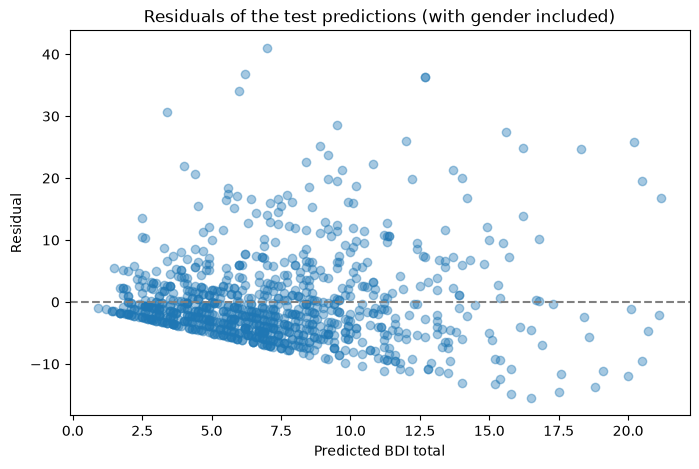

In [20]:
results["residual"] = (y_test.values - y_pred).round(1)
results.head(10)

plt.figure(figsize=(8, 5))
plt.scatter(results["predicted_bdi_total"], results["residual"], alpha=0.4)
plt.axhline(0, linestyle="--", color="grey")
plt.xlabel("Predicted BDI total")
plt.ylabel("Residual")
plt.title("Residuals of the test predictions (with gender included)")
plt.show()

## **Explanation**

- The residuals still aren't randomly scattered around zero — the same compression pattern from before persists: strongly positive residuals (actual > predicted) at low predicted values, more negative residuals at high predicted values.
- The spread of predictions is broadly similar to the gender-only model (test R² 0.220 vs 0.227 before the `sqi_*` fix) — removing the redundant raw sleep items cost very little real predictive power, because that power wasn't really there: it was the same signal counted five times instead of once.
- This tells us the model's real limitation isn't the feature set's size, it's that screen time, sleep quality, and gender together still don't give the model enough confidence to spread predictions across the full BDI range — there's likely more unexplained signal (other life circumstances, other symptom dimensions) still missing from the feature set.

## **What this means for the presentation**
The honest, final story: adding gender meaningfully improved the model (R² 0.193 → 0.227 → 0.220 once the sleep composite's redundant raw items were also removed). Gender remains the single strongest individual predictor, and the feature set is now free of multicollinearity in both the screen-time and sleep-quality variables. The core limitation remains — the model still only explains about 22% of BDI variation, and it still compresses its predictions rather than confidently spreading them to match the true range of scores. That's a cleaner, more defensible finding than either earlier version, without overstating what the model can actually do.

---
## **Back to the threshold question**

The model predicts a score, but the original question was about crossing the clinical threshold. Since `depressed` is defined as `bdi_total >= 14`, the same rule can be applied to the **predicted** scores: anyone predicted to score 14 or above is labelled "depressed", and everyone else "not depressed". These labels are then compared with the real `depressed` values in the test set. This only adds a cut-off to the existing predictions; no new model is fitted.

In [21]:
threshold = 14

actual_above = y_test >= threshold

for cutoff in [14, 10]:
    predicted_above = pd.Series(y_pred >= cutoff, index=y_test.index)
    table = pd.crosstab(actual_above.rename("Actually >= 14"), predicted_above.rename(f"Predicted >= {cutoff}"))
    caught = int((actual_above & predicted_above).sum())
    wrongly_flagged = int((~actual_above & predicted_above).sum())
    accuracy = ((actual_above == predicted_above).mean())
    print(f"--- Cut-off on predicted score: {cutoff} ---")
    print(table)
    print(f"Flagged: {int(predicted_above.sum())} | caught {caught} of {int(actual_above.sum())} "
          f"actual cases ({caught / actual_above.sum():.1%}) | wrongly flagged {wrongly_flagged}")
    print(f"Accuracy: {accuracy:.1%}\n")

print(f"Accuracy of always predicting 'not depressed': {1 - actual_above.mean():.1%}")
print(f"Highest predicted score in the test set: {y_pred.max():.1f}")

--- Cut-off on predicted score: 14 ---
Predicted >= 14  False  True 
Actually >= 14               
False              794     22
True               119     27
Flagged: 49 | caught 27 of 146 actual cases (18.5%) | wrongly flagged 22
Accuracy: 85.3%

--- Cut-off on predicted score: 10 ---
Predicted >= 10  False  True 
Actually >= 14               
False              708    108
True                75     71
Flagged: 179 | caught 71 of 146 actual cases (48.6%) | wrongly flagged 108
Accuracy: 81.0%

Accuracy of always predicting 'not depressed': 84.8%
Highest predicted score in the test set: 21.2


## **Explanation**

- Did not edit this - both models are very similar but the model with individual features is very slightly better.

- **Applying the cut-off of 14 to the predicted scores catches few of the real cases.** Of the 146 adolescents in the test set who actually score 14 or above, only 26 (about 18%) are predicted to be at or above 14, so 120 are missed. Only 46 adolescents are flagged at all, and 20 of them are wrongly flagged.
- **The overall accuracy of 85.4% is misleading.** Always predicting "not depressed" would already be right 84.8% of the time, because most adolescents are below the threshold. The model improves on that by less than one percentage point.
- **This is the compression pattern again.** The model's predicted scores only reach about 22, and very few exceed 14, because the model pulls predictions toward the middle. A cut-off at 14 therefore rarely triggers.
- **Lowering the cut-off trades one error for another.** At a cut-off of 10, 68 of the 146 real cases are caught (about 47%), but 114 adolescents who are below the threshold are wrongly flagged, and accuracy falls to 80.0%.

## **Summary of findings**

- Screen time, sleep quality and gender together explain about 22% of the variation in BDI-II scores (test R² of 0.220, MAE of 4.89 points). Gender has the largest coefficient (+3.19), followed by sleep quality (+2.63) and screen time (+1.09).
- Training and test results are close, so the model is not overfitting, but 22% is a modest share: most of what separates one adolescent's score from another's is not captured by these variables.
- The threshold check shows the practical consequence. The model identifies factors that go with higher scores, but it is **not** reliable for picking out individual adolescents above the clinical cut-off of 14 (about 18% caught at a cut-off of 14).

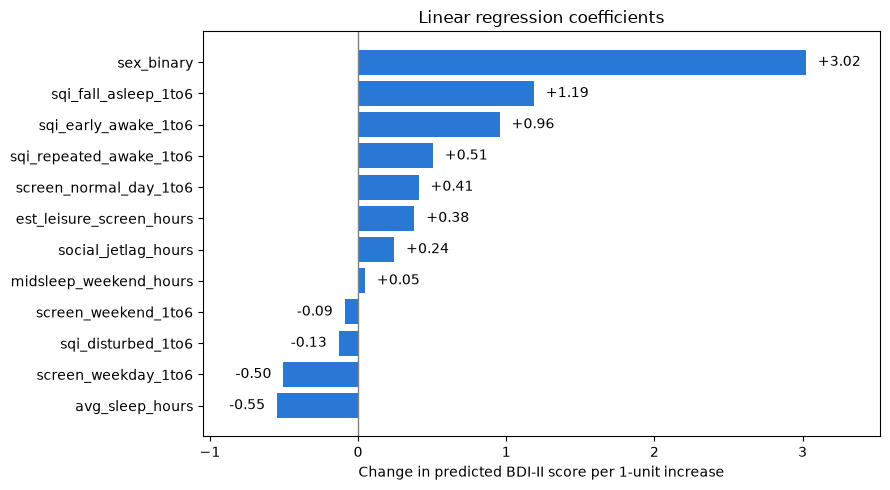

In [22]:
# Slide 2, visual 1: coefficients (BDI points per 1-unit increase in each predictor)
coef_plot = coefficients.sort_values()

plt.figure(figsize=(9, 5))
bars = plt.barh(coef_plot.index, coef_plot.values, color="#2a78d6")
for bar, value in zip(bars, coef_plot.values):
    plt.text(value + (0.08 if value >= 0 else -0.08), bar.get_y() + bar.get_height() / 2,
             f"{value:+.2f}", va="center", ha="left" if value >= 0 else "right")
plt.axvline(0, color="grey", linewidth=1)
plt.xlim(coef_plot.min() - 0.5, coef_plot.max() + 0.5)
plt.xlabel("Change in predicted BDI-II score per 1-unit increase")
plt.title("Linear regression coefficients")
plt.tight_layout()
plt.savefig("slide2_coefficients.png", dpi=200, bbox_inches="tight")
plt.show()

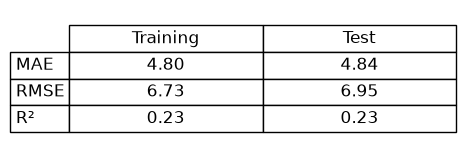

In [23]:
# Slide 2, visual 2: train vs test metrics table
table_data = metrics.loc[["MAE", "RMSE", "R²"]]
cell_text = [[f"{v:.2f}" for v in row] for row in table_data.values]

fig, ax = plt.subplots(figsize=(5, 1.8))
ax.axis("off")
tbl = ax.table(cellText=cell_text, rowLabels=table_data.index,
               colLabels=table_data.columns, cellLoc="center", loc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(12)
tbl.scale(1, 1.6)
plt.savefig("slide2_metrics.png", dpi=200, bbox_inches="tight")
plt.show()

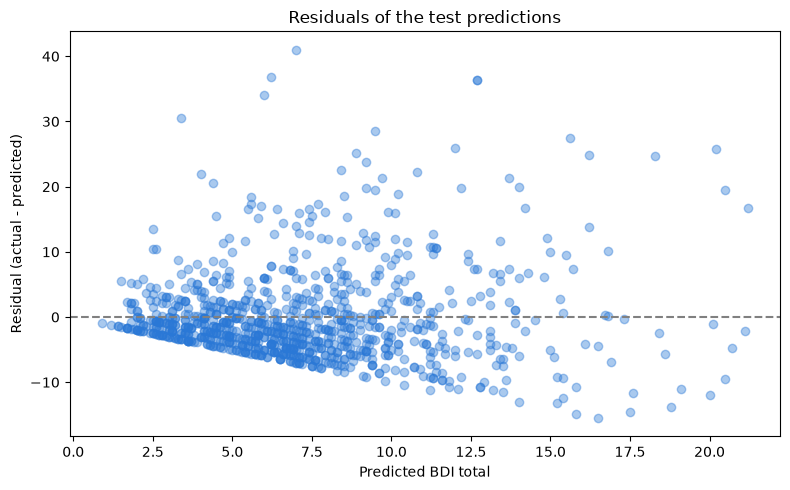

In [24]:
# Slide 2, visual 3: residual plot saved as an image
plt.figure(figsize=(8, 5))
plt.scatter(results["predicted_bdi_total"], results["residual"], alpha=0.4, color="#2a78d6")
plt.axhline(0, linestyle="--", color="grey")
plt.xlabel("Predicted BDI total")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residuals of the test predictions")
plt.tight_layout()
plt.savefig("slide2_residuals.png", dpi=200, bbox_inches="tight")
plt.show()
